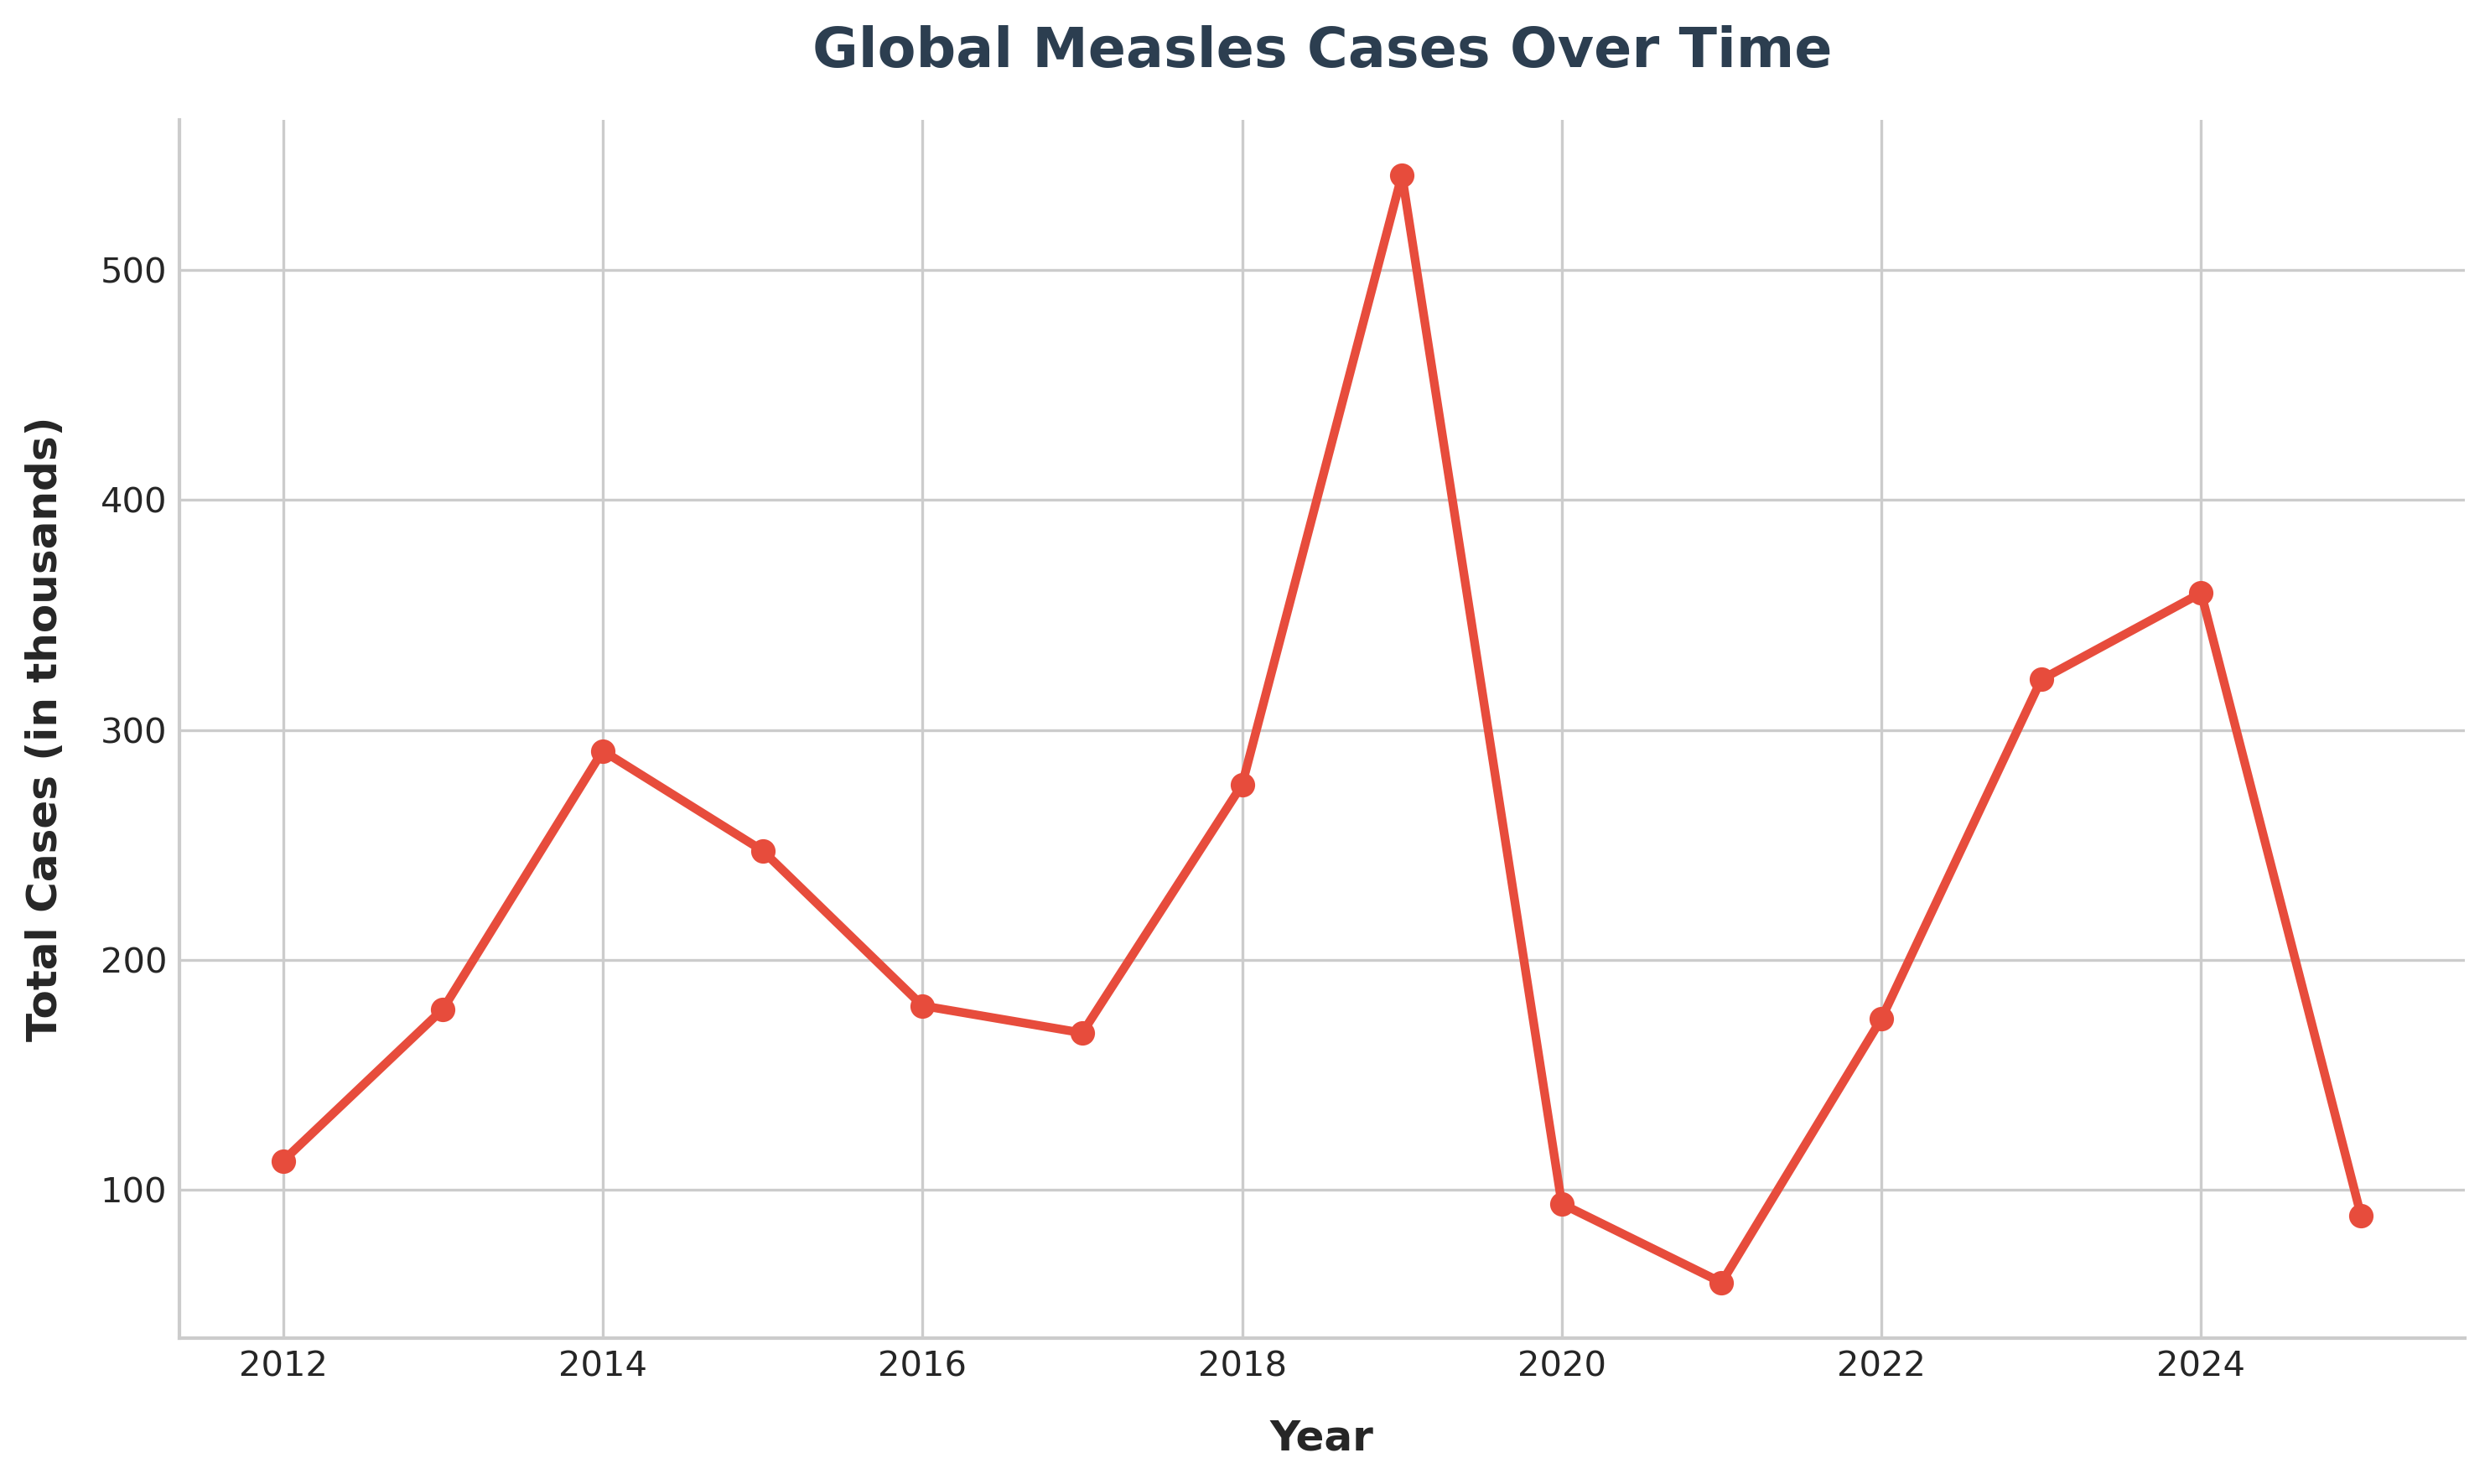

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Load the dataset directly from GitHub
url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2025/2025-06-24/cases_year.csv"
df = pd.read_csv(url)

# 2. Clean and convert relevant columns to numeric types
df["measles_total"] = pd.to_numeric(df["measles_total"], errors="coerce")
df["year"] = pd.to_numeric(df["year"], errors="coerce")

# 3. Aggregate total measles cases globally by year
global_trend = (
    df.groupby("year")["measles_total"].sum().reset_index().dropna()
)

# 4. Set up a modern plotting style
plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(10, 6), dpi=300)

# 5. Plot the trend line
ax.plot(
    global_trend["year"],
    global_trend["measles_total"] / 1e3,  # Convert to thousands for readability
    marker="o",
    color="#e74c3c",
    linewidth=2.5,
    markersize=6,
    label="Global Measles Cases",
)

# 6. Customize labels, title, and appearance
ax.set_title(
    "Global Measles Cases Over Time",
    fontsize=16,
    fontweight="bold",
    pad=15,
    color="#2c3e50",
)
ax.set_xlabel("Year", fontsize=12, fontweight="bold", labelpad=10)
ax.set_ylabel(
    "Total Cases (in thousands)", fontsize=12, fontweight="bold", labelpad=10
)

# Clean up spines and ticks
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="both", which="major", labelsize=10)

plt.tight_layout()
plt.show()